# Чекпойнт 2. Разведочный анализ данных

**Проект:** мультиагентная система на основе LLM для генерации и проверки математических задач (тема № 99)
**Автор:** Борщев Аристарх Александрович · **Куратор:** Голубев Александр · **Трек:** DL (NLP) с исследовательской частью

Модели в проекте не обучаются, поэтому данные нужны для **оценки агентов** (задачи с эталонным ответом и решением) и для понимания, **как устроены темы и сложность**. Свой банк заданий МЦКО / ОГЭ собирается позже; здесь анализируются открытые наборы, которые станут набором для оценки:

| Набор | Объём | Что внутри |
|---|---|---|
| GSM8K | 8 792 | Текстовые задачи 2–8 классов, решение с разметкой вычислений, числовой ответ |
| MATH | 12 500 | Задачи экзаменов и олимпиад США: 7 разделов, уровни 1–5, решение в LaTeX |
| miniF2F | 488 | Задачи MATH, AMC, AIME, IMO, формализованные в Lean 4 (исследовательская часть) |

In [1]:
import json, re, os, glob, random, subprocess, urllib.request, warnings
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sympy as sp

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA = "data"
os.makedirs(DATA, exist_ok=True)
URLS = {
    "gsm8k_train.jsonl": "https://raw.githubusercontent.com/openai/grade-school-math/master/grade_school_math/data/train.jsonl",
    "gsm8k_test.jsonl":  "https://raw.githubusercontent.com/openai/grade-school-math/master/grade_school_math/data/test.jsonl",
    "math_train.jsonl":  "https://media.githubusercontent.com/media/openai/prm800k/main/prm800k/math_splits/train.jsonl",
    "math_test.jsonl":   "https://media.githubusercontent.com/media/openai/prm800k/main/prm800k/math_splits/test.jsonl",
}
for name, url in URLS.items():
    if not os.path.exists(f"{DATA}/{name}"):
        urllib.request.urlretrieve(url, f"{DATA}/{name}")
read = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]

rows = []
for split in ["train", "test"]:
    for r in read(f"{DATA}/gsm8k_{split}.jsonl"):
        sol, ans = r["answer"].rsplit("####", 1)
        rows.append(dict(source="GSM8K", split=split, problem=r["question"], solution=sol.strip(),
                         answer=ans.strip(), subject=None, level=None))
    for r in read(f"{DATA}/math_{split}.jsonl"):
        rows.append(dict(source="MATH", split=split, problem=r["problem"], solution=r["solution"],
                         answer=r.get("answer"), subject=r["subject"], level=r["level"]))
df = pd.DataFrame(rows)
df["level"] = df["level"].astype("Int64")

## 1. Признаки и основные статистики

Из текста извлечены признаки: длина условия и решения (слов), число шагов решения, количество чисел в условии, доля LaTeX в условии, наличие рисунка `[asy]` и тип ответа.

In [2]:
def n_steps(r):
    if r.source == "GSM8K":
        return len([l for l in r.solution.split("\n") if l.strip()])
    t = re.sub(r"\$[^$]*\$", "X", r.solution)
    return max(1, len([s for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()]))

def answer_type(a):
    a = str(a or "").replace(",", "").replace("$", "").strip()
    if not a or a == "None":                       return "нет ответа"
    if re.fullmatch(r"-?\d+", a):                  return "целое"
    if re.fullmatch(r"-?\d*\.\d+", a):             return "десятичное"
    if re.fullmatch(r"-?\\[dt]?frac\{-?\d+\}\{\d+\}|-?\d+/\d+", a): return "дробь"
    if re.search(r"\\sqrt|\\pi", a):               return "корень / π"
    if re.search(r"^[\(\[].*[\)\]]$", a):          return "кортеж / интервал"
    if re.search(r"\\text|^[A-Za-z]+$", a):        return "текст"
    return "выражение"

df["problem_words"]  = df.problem.str.split().str.len()
df["solution_words"] = df.solution.str.split().str.len()
df["n_steps"]        = df.apply(n_steps, axis=1)
df["n_numbers"]      = df.problem.str.count(r"\d+(?:\.\d+)?")
# в GSM8K знак $ — это доллары, а не формула
df["latex_share"]    = np.where(df.source == "MATH", df.problem.apply(
    lambda s: sum(map(len, re.findall(r"\$[^$]*\$", s))) / len(s)), 0.0)
df["has_figure"]     = df.problem.str.contains(r"\[asy\]") | df.solution.str.contains(r"\[asy\]")
df["answer_type"]    = df.answer.apply(answer_type)

df.drop(columns=["problem", "solution"]).describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
source,21292,2,MATH,12500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,21292,2,train,19473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answer,21292,4874,2,545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject,12500,7,Algebra,2931,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level,12500.0,<NA>,<NA>,<NA>,3.47344,1.292002,1.0,2.0,4.0,5.0,5.0
problem_words,21292.0,NaN,NaN,NaN,37.516579,23.512351,2.0,22.0,34.0,48.0,279.0
solution_words,21292.0,NaN,NaN,NaN,72.035882,62.602747,1.0,34.0,55.0,88.0,915.0
n_steps,21292.0,NaN,NaN,NaN,3.549361,2.260532,1.0,2.0,3.0,4.0,32.0
n_numbers,21292.0,NaN,NaN,NaN,5.971304,12.117168,0.0,2.0,4.0,5.0,379.0
latex_share,21292.0,NaN,NaN,NaN,0.127256,0.201108,0.0,0.0,0.0,0.2,0.961538


У MATH условия короче, а решения длиннее и разнообразнее, чем у GSM8K. Распределения длин скошены вправо: есть длинный хвост, он разобран в разделе о выбросах.

## 2. Пропуски

In [3]:
print((df.isna().mean() * 100).round(1)[lambda s: s > 0].astype(str) + " %")
pd.crosstab(df.source, df.subject.isna(), colnames=["subject пуст"])

subject    41.3 %
level      41.3 %
dtype: object


subject пуст,False,True
source,,
GSM8K,0,8792
MATH,12500,0


Пропуски в `subject` и `level` (41 %) **структурные**: их нет ни у одной задачи MATH и есть у всех задач GSM8K, потому что у этого набора просто нет такой разметки. Заполнять их модой бессмысленно, поэтому GSM8K получает собственную категорию: `subject = "Word problems"`, `level = 0` (проще уровня 1 MATH).

In [4]:
df["subject"] = df.subject.fillna("Word problems")
df["level"] = df.level.fillna(0).astype(int)

## 3. Ошибки в данных

Для текстовых задач ошибка — это неверная разметка. Проверяем три вещи: пересчитываем все вычисления GSM8K вида `<<48/2=24>>`, сравниваем ответ MATH с `\boxed{}` в решении, ищем дубликаты и пересечение train и test.

In [5]:
CALC = re.compile(r"<<([^=<>]+)=([^<>]+)>>")
calc = Counter()
for sol in df[df.source == "GSM8K"].solution:
    for expr, res in CALC.findall(sol):
        e = expr.replace(",", "").replace("x", "*")
        try:
            calc["верно" if abs(eval(e, {"__builtins__": {}}) - float(res.replace(",", ""))) < 1e-6 else "ошибка"] += 1
        except Exception:
            calc["не вычисляется"] += 1
print("GSM8K, вычисления в решениях:", dict(calc))

def last_boxed(s):
    i = s.rfind("\\boxed{")
    if i < 0: return None
    depth, j = 0, i + 6
    for k in range(j, len(s)):
        depth += {"{": 1, "}": -1}.get(s[k], 0)
        if depth == 0: return s[j + 1:k]
mm = df[df.source == "MATH"]
boxed = mm.solution.apply(last_boxed)
print("MATH, ответ совпадает с \\boxed{}:", int((boxed == mm.answer).sum()), "| нет \\boxed{}:", int(boxed.isna().sum()))

key = df.problem.str.strip().str.lower()
print("Дубликатов условий:", int(df.assign(k=key).duplicated(["source", "k"]).sum()))
for src in ["GSM8K", "MATH"]:
    s = df.source == src
    print(f"{src}: общих задач в train и test —", len(set(key[s & (df.split == "train")]) & set(key[s & (df.split == "test")])))

df = df[~df.assign(k=key).duplicated(["source", "k"])]
df = df[df.answer_type != "нет ответа"].reset_index(drop=True)
print("Осталось задач:", len(df))

GSM8K, вычисления в решениях: {'верно': 27997, 'не вычисляется': 1}
MATH, ответ совпадает с \boxed{}: 12471 | нет \boxed{}: 2
Дубликатов условий: 1
GSM8K: общих задач в train и test — 0
MATH: общих задач в train и test — 0
Осталось задач: 21287


**Данные чистые.** Все ~28 тыс. вычислений GSM8K верны, ответы MATH совпадают с `\boxed{}` в решениях (единичные расхождения — пробелы и `\dfrac` вместо `\frac`), дубликат один, утечки между train и test нет. Удалены дубликат и задачи без ответа.

Следствие для проекта: **готовых ошибочных решений в данных нет**, поэтому для оценки проверяющего ошибки придётся вносить искусственно (раздел 7).

## 4. Выбросы

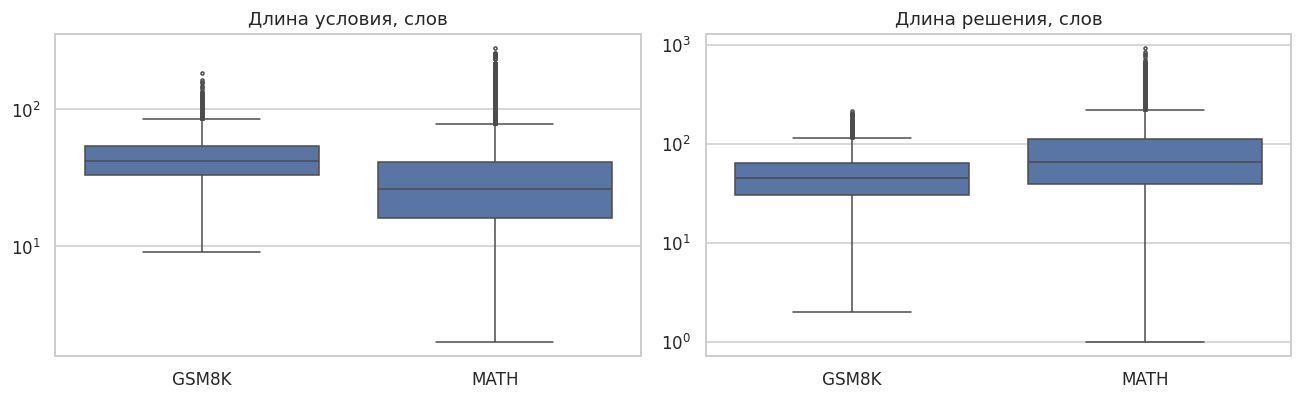

Доля выбросов (IQR, k=3): {'GSM8K': 0.5, 'MATH': 4.7}
Среди задач с рисунком: 12% | без рисунка: 2%
Задач с текстовым ответом (вне автоматической проверки): 267


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, t in zip(axes, ["problem_words", "solution_words"], ["Длина условия, слов", "Длина решения, слов"]):
    sns.boxplot(data=df, x="source", y=col, ax=ax, fliersize=2); ax.set_yscale("log")
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

def iqr_out(s, k=3):
    q1, q3 = s.quantile([.25, .75]); return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))
df["outlier"] = pd.concat([df.groupby("source")[c].transform(iqr_out)
                           for c in ["problem_words", "solution_words", "n_steps"]], axis=1).any(axis=1)
print("Доля выбросов (IQR, k=3):", (df.groupby("source").outlier.mean() * 100).round(1).to_dict())
print("Среди задач с рисунком:", f"{df[df.has_figure].outlier.mean():.0%}", "| без рисунка:", f"{df[~df.has_figure].outlier.mean():.0%}")
print("Задач с текстовым ответом (вне автоматической проверки):", int((df.answer_type == "текст").sum()))

In [7]:
# Опечатки в разметке: незакрытый $ или несбалансированные {} ломают формулу в боте
def latex_broken(s):
    t = re.sub(r"\\[\$\{\}]", "", s)                       # экранированные \$ \{ \} — не разметка
    t = re.sub(r"\[asy\].*?\[/asy\]", "", t, flags=re.S)
    return t.count("$") % 2 == 1 or t.count("{") != t.count("}")

m_ = df[df.source == "MATH"]
broken = m_[m_.problem.apply(latex_broken) | m_.solution.apply(latex_broken)]
print("MATH: задач с битой разметкой:", len(broken))
for sol in broken.solution:
    print("…", re.search(r".{0,40}\$\d+ (?:dollars|as well).{0,30}", sol).group(0) if re.search(r"\$\d+ (?:dollars|as well)", sol) else sol[:80])

MATH: задач с битой разметкой: 2
…  amount borrowed. Since he has to repay $10 as well as $\$1.5x$ in interest, we h
… ide. Since we know that Ann was charged $120 dollars a 50 mile taxi ride, we can s


Выбросов немного: около 0,5 % в GSM8K и 5 % в MATH. **Опечаток в разметке** практически нет: 2 задачи, и в обеих в тексте решения стоит знак доллара без экранирования (`$120 dollars`), из-за чего ломается следующая формула. Они исключаются из образцов для генератора и из набора для оценки. Задачи с рисунком становятся выбросами в 6 раз чаще: код `[asy]` раздувает текст, хотя сама задача не обязательно сложная. **Удалять их не нужно**, это реальные задачи; но при подсчёте стоимости (токенов) их стоит учитывать отдельно. Задачи с текстовым ответом (вариант «C», день недели) исключаются из автоматической оценки: SymPy их не проверит.

## 5. Баланс тем и уровней

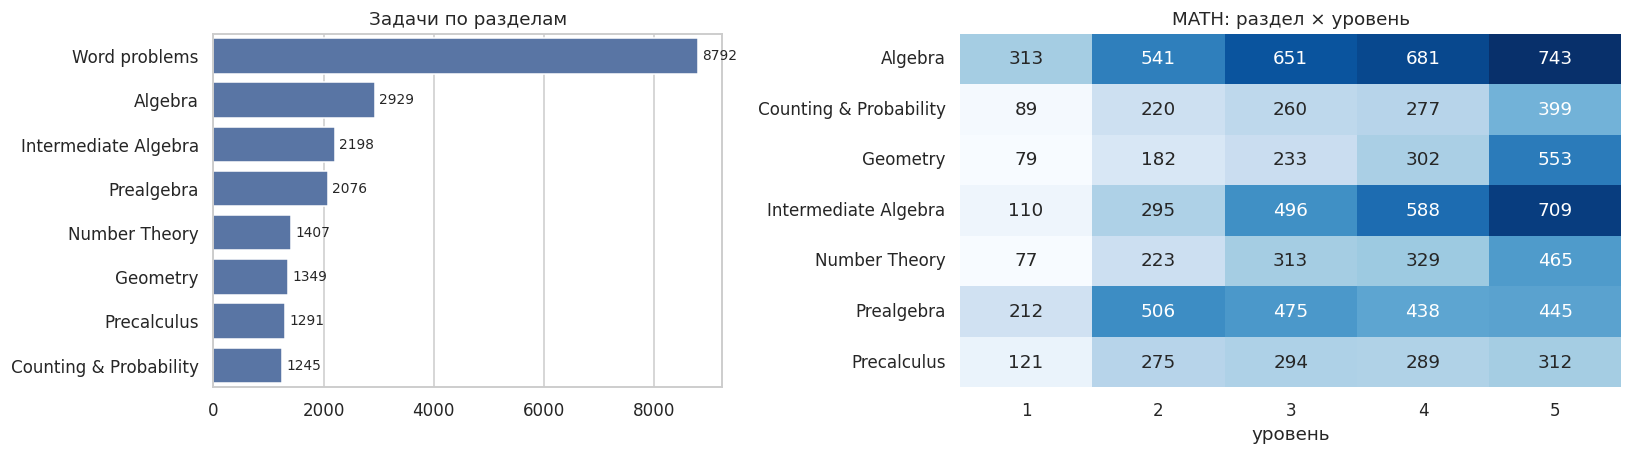

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw=dict(width_ratios=[1, 1.3]))
order = df.subject.value_counts().index
sns.countplot(data=df, y="subject", order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("Задачи по разделам"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
for c in axes[0].containers: axes[0].bar_label(c, padding=3, fontsize=9)
pv = pd.crosstab(df[df.source == "MATH"].subject, df[df.source == "MATH"].level)
sns.heatmap(pv, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("MATH: раздел × уровень"); axes[1].set_xlabel("уровень"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

Разделы и уровни несбалансированы: алгебры и текстовых задач много, геометрии и вероятностей мало; уровня 5 больше всего, уровня 1 меньше всего. Если считать среднюю точность по всему набору, она будет отражать в основном алгебру высокого уровня. Поэтому **набор для оценки собираем стратифицированно**: поровну задач на каждую пару «раздел × уровень».

## 6. Что определяет сложность

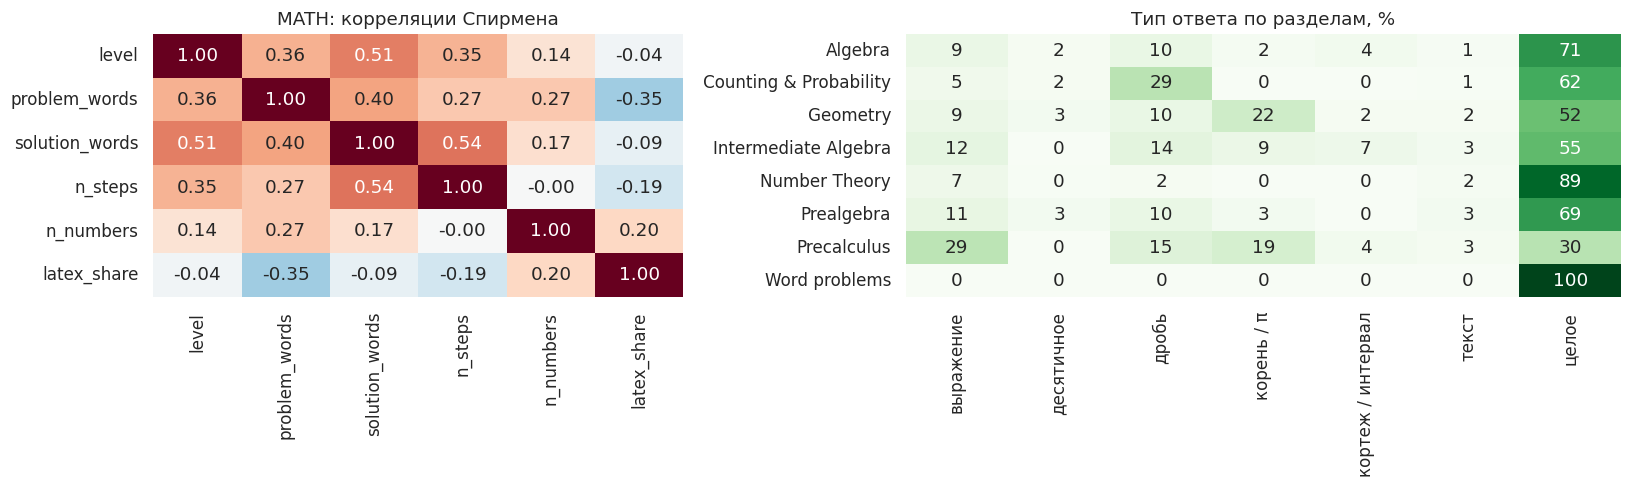

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 1.35]))
feat = ["level", "problem_words", "solution_words", "n_steps", "n_numbers", "latex_share"]
sns.heatmap(df[df.source == "MATH"][feat].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("MATH: корреляции Спирмена")
at = pd.crosstab(df.subject, df.answer_type, normalize="index") * 100
sns.heatmap(at, annot=True, fmt=".0f", cmap="Greens", cbar=False, ax=axes[1])
axes[1].set_title("Тип ответа по разделам, %"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

- **Сложность сильнее всего связана с длиной решения** (ρ ≈ 0,51), с длиной условия и числом шагов — умеренно (≈ 0,35). Сложную задачу можно сформулировать коротко, поэтому методист должен оценивать сложность по решению, а не только по условию.
- **Тип ответа зависит от раздела.** В текстовых задачах и теории чисел почти всегда целое число, в тригонометрии и алгебре высокого уровня — выражения, корни, интервалы. Один ответ можно записать по-разному (`\frac{1}{2}`, `0.5`), поэтому ответы сравниваем через SymPy, а не как строки. Начинать прототип стоит с разделов с целыми ответами.

## 7. Бейзлайн

Простейшая модель — TF-IDF + логистическая регрессия: по тексту условия предсказывает раздел и уровень. Она же может служить дешёвым фильтром перед LLM-методистом. Это качество — точка отсчёта на год.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error

tr, te = df[df.split == "train"], df[df.split == "test"]
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                      token_pattern=r"(?u)\\?[A-Za-z]+|\d+|[^\sA-Za-z\d]")
Xtr, Xte = vec.fit_transform(tr.problem), vec.transform(te.problem)

clf = LogisticRegression(max_iter=2000, C=5).fit(Xtr, tr.subject)
pred = clf.predict(Xte)
math_te = te.source.values == "MATH"
print(f"Раздел: accuracy {accuracy_score(te.subject, pred):.3f}, только MATH {accuracy_score(te.subject[math_te], pred[math_te]):.3f}")

mtr, mte = tr[tr.source == "MATH"], te[te.source == "MATH"]
lvl = LogisticRegression(max_iter=2000, C=2).fit(vec.transform(mtr.problem), mtr.level)
pl = lvl.predict(vec.transform(mte.problem))
print(f"Уровень: accuracy {accuracy_score(mte.level, pl):.3f}, MAE {mean_absolute_error(mte.level, pl):.3f} "
      f"(константа: MAE {mean_absolute_error(mte.level, np.full(len(mte), int(mtr.level.median()))):.3f})")

names = vec.get_feature_names_out()
pd.Series({c: ", ".join(names[np.argsort(clf.coef_[i])[-6:][::-1]]) for i, c in enumerate(clf.classes_)},
          name="самые характерные токены").to_frame()

Раздел: accuracy 0.937, только MATH 0.780
Уровень: accuracy 0.406, MAE 0.870 (константа: MAE 1.096)


,самые характерные токены
Algebra,"$, $ ., arithmetic sequence, $ \, evaluate, ^"
Counting & Probability,"probability, the probability, !, probability t..."
Geometry,"$ ., volume, radius, triangle, pyramid, \triangle"
Intermediate Algebra,". $, x ^, |, , $, +, ellipse"
Number Theory,"base, _, \pmod, in base, digit, \pmod {"
Prealgebra,"simplify, \div, what, + (, $ \sqrt, average"
Precalculus,"\sin, \cos, . $, \tan, \pi, \theta"
Word problems,". how, he, much, how much, . if, ."


**Раздел определяется хорошо** (≈ 0,94 в целом, ≈ 0,78 на одних задачах MATH), характерные токены осмысленные: `probability`, `\pmod`, `\sin`, `triangle`. **Уровень определяется слабо**: ошибка почти в целый уровень, лишь немного лучше константы. Это подтверждает раздел 6: по формулировке сложность видна плохо.

## 8. Аугментации

Модели не обучаются, поэтому аугментации нужны для пополнения набора для оценки. Две самые полезные — ниже.

In [11]:
def renumber(problem, solution, seed):
    # Новые числа в условии, ответ пересчитывается по разметке решения через SymPy
    rnd = random.Random(seed)
    nums = set(re.findall(r"(?<![\d.])\d+(?![\d.])", problem))
    env = {n: str(max(2, int(int(n) * rnd.uniform(.6, 1.6)))) for n in nums}
    new_p = re.sub(r"(?<![\d.])\d+(?![\d.])", lambda m: env.get(m.group(), m.group()), problem)
    val = None
    for expr, res in CALC.findall(solution):
        e = re.sub(r"(?<![\d.])\d+(?:\.\d+)?(?![\d.])", lambda m: env.get(m.group(), m.group()), expr.replace(",", ""))
        try: val = sp.nsimplify(sp.sympify(e))
        except Exception: return None
        if not isinstance(val, sp.Number): return None
        env[res.replace(",", "")] = str(val)
    return new_p, val

def inject_error(solution, seed):
    # Ошибка в одном шаге решения — для оценки проверяющего
    rnd = random.Random(seed)
    expr, res = rnd.choice(CALC.findall(solution))
    wrong = str(int(float(res.replace(",", ""))) + rnd.choice([-2, -1, 1, 2, 10]))
    return solution.replace(f"<<{expr}={res}>>{res}", f"<<{expr}={wrong}>>{wrong}", 1)

ex = df[df.source == "GSM8K"].iloc[0]
print("Исходная:", ex.problem, "→", ex.answer)
print("Новые числа:", *renumber(ex.problem, ex.solution, 1), sep="\n")
print("\nРешение с внесённой ошибкой:\n" + inject_error(ex.solution, 3))

ok = [renumber(r.problem, r.solution, 2) for _, r in df[df.source == "GSM8K"].sample(500, random_state=0).iterrows()]
print(f"\nЗамена чисел дала целый положительный ответ в {np.mean([bool(o and o[1] is not None and o[1].is_integer and o[1] > 0) for o in ok]):.0%} задач")

Исходная: Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May? → 72
Новые числа:
Natalia sold clips to 35 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?
105/2

Решение с внесённой ошибкой:
Natalia sold 48/2 = <<48/2=34>>34 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.

Замена чисел дала целый положительный ответ в 62% задач


| Способ | Подходит? |
|---|---|
| **Замена чисел с пересчётом ответа** | Да, с фильтром: проверяет, что решатель не запомнил ответ. Целый ответ получается в ~60 % задач, остальные (как «полклиента» выше) отбрасываются |
| **Внесение ошибок в решения** | Да, ключевой: в данных нет ошибочных решений, а так известно, где ошибка, и можно мерить полноту проверяющего. Ограничение: ошибка не распространяется на следующие шаги (в примере выше второй шаг по-прежнему использует 24), поэтому её найти легче, чем настоящую. Следующая версия будет пересчитывать решение от ошибочного шага |
| **Перевод на русский через LLM** | Да: ответ при переводе не меняется, корректность легко проверить |
| **Перефразирование через LLM** | Частично: может незаметно изменить смысл, нужна проверка ответа |
| Опечатки, перестановка слов | Нет: в математике одна опечатка меняет задачу |

## 9. Исследовательская часть: проверка в Lean

SymPy проверяет ответ, но не рассуждение. Lean 4 проверяет доказательство строго — при условии, что LLM правильно переведёт задачу на Lean (автоформализация). Измерять точность такого перевода можно по эталонным формализациям **miniF2F**.

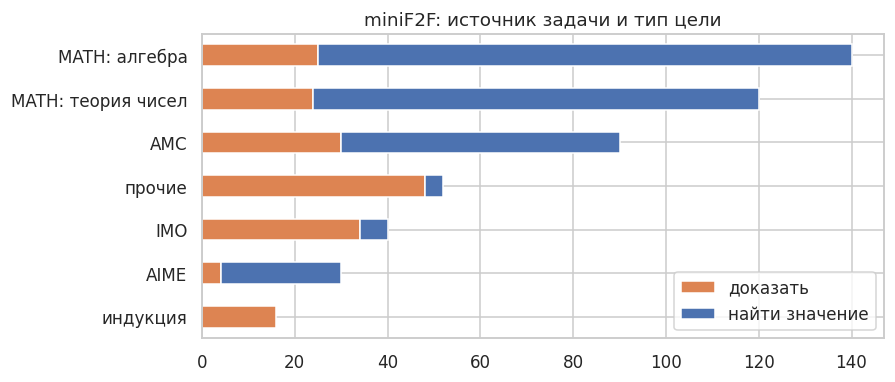

Задач из MATH: 53%; из них «найти значение»: 81%


In [12]:
MF = f"{DATA}/miniF2F-lean4"
if not os.path.exists(MF):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/yangky11/miniF2F-lean4", MF], check=True)

def family(n):
    for p, f in [("mathd_algebra", "MATH: алгебра"), ("mathd_numbertheory", "MATH: теория чисел"),
                 ("amc", "AMC"), ("aime", "AIME"), ("imo", "IMO"), ("induction", "индукция")]:
        if n.startswith(p): return f
    return "прочие"

lr = []
for path in glob.glob(f"{MF}/MiniF2F/*/*.lean"):
    m = re.search(r"theorem\s+(\S+)(.*?):=\s*by", open(path, encoding="utf-8").read(), re.S)
    concl = m.group(2).rsplit(":", 1)[-1].strip()
    is_value = (" = " in concl and not re.search(r"[↔∧∨∀∃¬≤≥<>≠→]", concl)
                and re.fullmatch(r"-?[\d\.\s/\(\)\+\-\*\^√]+", concl.rsplit(" = ", 1)[1].strip()))
    lr.append(dict(family=family(m.group(1)), goal="найти значение" if is_value else "доказать"))
lean = pd.DataFrame(lr)

ct = pd.crosstab(lean.family, lean.goal)
ct.loc[ct.sum(axis=1).sort_values().index].plot.barh(stacked=True, figsize=(8, 3.6), color=["#DD8452", "#4C72B0"])
plt.title("miniF2F: источник задачи и тип цели"); plt.ylabel(""); plt.legend(title=""); plt.show()
print(f"Задач из MATH: {lean.family.str.startswith('MATH').mean():.0%}; "
      f"из них «найти значение»: {(lean[lean.family.str.startswith('MATH')].goal == 'найти значение').mean():.0%}")

Половина miniF2F — задачи из MATH, только алгебра и теория чисел, и около 80 % из них имеют вид «найти значение» (`n = 70`) — это формат МЦКО и ОГЭ с кратким ответом. Значит, **формальная проверка в Lean реалистична для алгебры и теории чисел**, а для геометрии и текстовых задач с сюжетом эталонов нет.

Исследовательские вопросы: (1) какую долю задач LLM формализует корректно — сверка с miniF2F; (2) какие ошибки ловит Lean, но пропускают SymPy и LLM-проверяющий; (3) сколько стоит формальная проверка.

## 10. Выводы

1. **Данных для оценки достаточно:** ~21 тыс. задач с эталонным ответом и решением.
2. **Данные чистые**, поэтому ошибочные решения для оценки проверяющего создаются аугментацией.
3. **Классы несбалансированы:** набор для оценки собираем стратифицированно по разделу и уровню.
4. **Ответы разнообразны по формату:** сравниваем их через SymPy, прототип начинаем с разделов с целыми ответами.
5. **Сложность по условию видна плохо:** методист оценивает её по решению и по образцам того же уровня.
6. **Бейзлайн:** раздел ≈ 0,78 accuracy на MATH, уровень MAE ≈ 0,87 — точка отсчёта для LLM-методиста.
7. **Lean** реалистичен для алгебры и теории чисел; эталоны miniF2F позволяют измерить точность автоформализации.
8. **Ограничение:** наборы англоязычные и не размечены по российским форматам, поэтому собственный банк МЦКО / ОГЭ остаётся обязательной частью проекта.